### Object Detection on ChestX-Det Dataset

This project focuses on detecting and localizing **13 chest diseases and abnormalities** in X-ray images using the **YOLO11 object detection model**.

The dataset contains chest X-ray images with bounding-box annotations for multiple findings per image. The annotations were converted from the original pixel-based format into the **YOLO annotation format** and prepared for model training, validation, and testing.

**Prepared by: Yossef Elshamey**


# imports

In [1]:
import warnings
warnings.filterwarnings("ignore")
import kagglehub
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageEnhance
import random
from collections import Counter
from sklearn.model_selection import train_test_split
!pip install -q ultralytics
from ultralytics import YOLO
import glob
import shutil
import joblib
import json



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 45.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 3.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [2]:
path = kagglehub.dataset_download("metformin/chexdet-image-and-annotations")
print(f"Dataset downloaded to: {path}")

Dataset downloaded to: /kaggle/input/datasets/metformin/chexdet-image-and-annotations


In [3]:
for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}  {file}")

    if level >= 2:
        dirs[:] = []

chexdet-image-and-annotations/
  DETR_sample/
    xception_with_GPTdepth2_BERTdepth3.h5
    efficientnetb2_with_GPTdepth1_BERTdepth3.h5
  test_data/
    test/
      41463.png
      59639.png
      48828.png
      45687.png
      41141.png
      69989.png
      68970.png
      45718.png
      41504.png
      40050.png
  train_data/
    train/
      41461.png
      61051.png
      45786.png
      46575.png
      59655.png
      55936.png
      40474.png
      70942.png
      69958.png
      57494.png
  ChestXDet_Metainformations/
    ChestX-Det-Dataset-main/
      ChestX_Det_test.json
      README.md
      ChestX_Det_train.json


In [4]:
file_extensions = Counter()

for root, dirs, files in os.walk(path):
    for file in files:
        ext = os.path.splitext(file)[1].lower()
        file_extensions[ext] += 1

print("File types:")

for ext, count in file_extensions.most_common():
    print(f"{ext or '[no extension]'}: {count}")

File types:
.png: 3580
.py: 3
.h5: 2
.json: 2
.md: 1
.txt: 1


In [5]:
image_extensions = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff"
}

image_files = []

for root, dirs, files in os.walk(path):
    for file in files:
        if os.path.splitext(file)[1].lower() in image_extensions:
            image_files.append(
                os.path.join(root, file)
            )

print("Number of images:", len(image_files))

print("\nFirst 10 images:")

for file in image_files[:10]:
    print(file)

Number of images: 3580

First 10 images:
/kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/41463.png
/kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/59639.png
/kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/48828.png
/kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/45687.png
/kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/41141.png
/kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/69989.png
/kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/68970.png
/kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/45718.png
/kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/41504.png
/kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/40050.png


In [6]:
train_json_path = os.path.join(
    path,
    "ChestXDet_Metainformations",
    "ChestX-Det-Dataset-main",
    "ChestX_Det_train.json"
)

test_json_path = os.path.join(
    path,
    "ChestXDet_Metainformations",
    "ChestX-Det-Dataset-main",
    "ChestX_Det_test.json"
)

with open(train_json_path, "r") as f:
    train_annotations = json.load(f)

with open(test_json_path, "r") as f:
    test_annotations = json.load(f)

print("Train annotation type:", type(train_annotations))
print("Test annotation type:", type(test_annotations))

print("Number of train records:", len(train_annotations))
print("Number of test records:", len(test_annotations))

Train annotation type: <class 'list'>
Test annotation type: <class 'list'>
Number of train records: 3025
Number of test records: 553


In [7]:
print("First train annotation:")
print(json.dumps(train_annotations[0], indent=2)[:5000])

First train annotation:
{
  "file_name": "36200.png",
  "syms": [],
  "boxes": [],
  "polygons": []
}


In [8]:
print("Train JSON type:", type(train_annotations))

if isinstance(train_annotations, dict):
    print("Train JSON keys:")
    print(train_annotations.keys())

elif isinstance(train_annotations, list):
    print("Train JSON contains", len(train_annotations), "records")
    print("First record type:", type(train_annotations[0]))

Train JSON type: <class 'list'>
Train JSON contains 3025 records
First record type: <class 'dict'>


In [9]:
annotated_train = [
    record for record in train_annotations
    if len(record.get("syms", [])) > 0
]
# saving photos that have annotaions

In [10]:
for record in annotated_train[:10]:
    print("=" * 80)
    print("File:", record["file_name"])
    print("Symbols:", record["syms"])
    print("Boxes:", record["boxes"])
    print("Number of symbols:", len(record["syms"]))
    print("Number of boxes:", len(record["boxes"]))

File: 36204.png
Symbols: ['Cardiomegaly', 'Nodule']
Boxes: [[387, 497, 752, 734], [233, 666, 258, 693]]
Number of symbols: 2
Number of boxes: 2
File: 36205.png
Symbols: ['Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Nodule', 'Cardiomegaly']
Boxes: [[884, 223, 957, 299], [414, 208, 499, 267], [605, 206, 648, 265], [631, 56, 672, 96], [102, 450, 175, 529], [73, 896, 106, 957], [64, 756, 110, 820], [98, 795, 152, 877], [857, 690, 931, 800], [880, 813, 935, 907], [825, 503, 884, 568], [213, 517, 255, 576], [167, 641, 246, 722], [135, 705, 177, 761], [127, 578, 161, 703], [170, 400, 190, 484], [339, 232, 402, 307], [688, 210, 746, 283], [858, 313, 910, 443], [159, 102, 214, 159], [933, 493, 1003, 593], [936, 689, 964, 826], [912, 816, 982, 990], [894, 493, 951, 697], [361, 593, 820, 826]]
Number of symbols: 2

# Class Distribution

In [11]:
all_symbols = []

for record in train_annotations + test_annotations:
    all_symbols.extend(record.get("syms", []))

unique_classes = sorted(set(all_symbols))

print("Number of classes:", len(unique_classes))

print("\nClasses:")
for i, class_name in enumerate(unique_classes):
    print(i, ":", class_name)

Number of classes: 13

Classes:
0 : Atelectasis
1 : Calcification
2 : Cardiomegaly
3 : Consolidation
4 : Diffuse Nodule
5 : Effusion
6 : Emphysema
7 : Fibrosis
8 : Fracture
9 : Mass
10 : Nodule
11 : Pleural Thickening
12 : Pneumothorax


In [12]:
class_counts = Counter(all_symbols)

print("Class distribution:\n")

for class_name, count in class_counts.most_common():
    print(f"{class_name}: {count}")

Class distribution:

Consolidation: 2563
Effusion: 2112
Nodule: 986
Fibrosis: 739
Fracture: 661
Pleural Thickening: 631
Calcification: 348
Atelectasis: 340
Emphysema: 298
Cardiomegaly: 293
Diffuse Nodule: 290
Pneumothorax: 211
Mass: 167


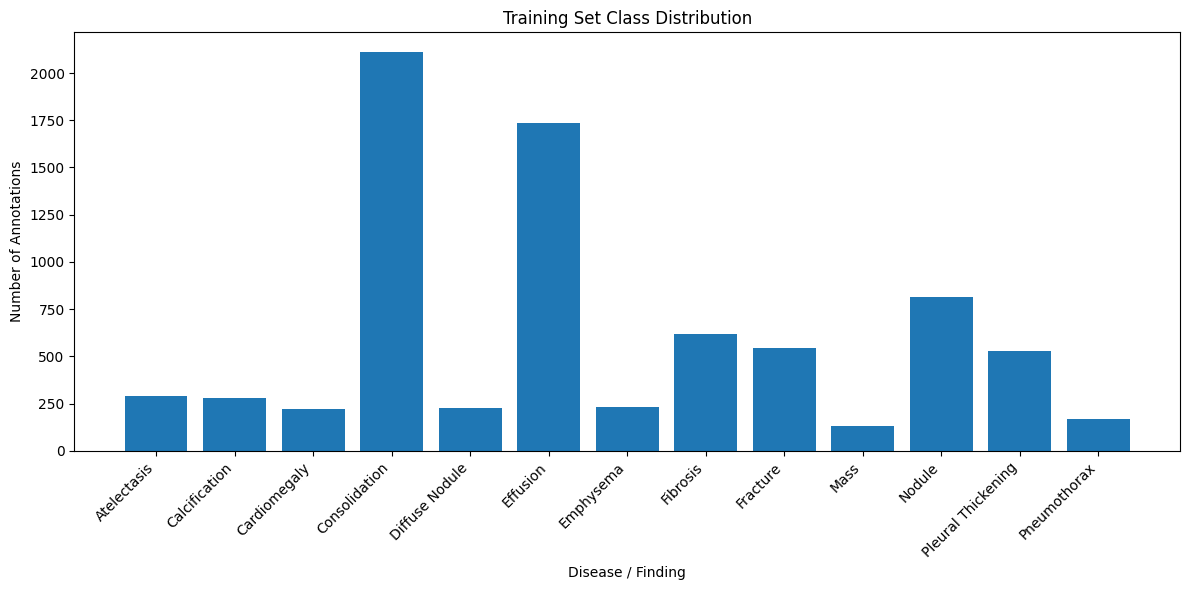

In [13]:
from collections import Counter
import matplotlib.pyplot as plt
class_names = [
    "Atelectasis",
    "Calcification",
    "Cardiomegaly",
    "Consolidation",
    "Diffuse Nodule",
    "Effusion",
    "Emphysema",
    "Fibrosis",
    "Fracture",
    "Mass",
    "Nodule",
    "Pleural Thickening",
    "Pneumothorax"
]
class_counts = Counter()

for record in train_annotations:
    for symbol in record.get("syms", []):
        class_counts[symbol] += 1

# Keep classes in our predefined order
counts = [
    class_counts[class_name]
    for class_name in class_names
]

plt.figure(figsize=(12, 6))

plt.bar(class_names, counts)

plt.xlabel("Disease / Finding")
plt.ylabel("Number of Annotations")
plt.title("Training Set Class Distribution")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

the data is imbalanced

# Check Image Dimensions

In [14]:
sample_files = [
    "36204.png",
    "36205.png",
    "36206.png",
    "36209.png"
]

for file_name in sample_files:
    image_path = None

    for root, dirs, files in os.walk(path):
        if file_name in files:
            image_path = os.path.join(root, file_name)
            break

    if image_path:
        with Image.open(image_path) as img:
            print(
                f"{file_name}: "
                f"width={img.width}, "
                f"height={img.height}, "
                f"mode={img.mode}"
            )

36204.png: width=1024, height=1024, mode=L
36205.png: width=1024, height=1024, mode=L
36206.png: width=1024, height=1024, mode=L
36209.png: width=1024, height=1024, mode=L


## Check All Bounding Boxes are valid

In [15]:
def check_boxes(records, dataset_name):
    total_boxes = 0
    invalid_boxes = 0
    invalid_records = []

    for record in records:
        file_name = record["file_name"]
        boxes = record.get("boxes", [])

        if not boxes:
            continue

        image_path = None

        for root, dirs, files in os.walk(path):
            candidate = os.path.join(root, file_name)

            if os.path.exists(candidate):
                image_path = candidate
                break

        if image_path is None:
            continue

        with Image.open(image_path) as img:
            width, height = img.size

        for box in boxes:
            total_boxes += 1

            if len(box) != 4:
                invalid_boxes += 1
                invalid_records.append((file_name, box, "wrong length"))
                continue

            x1, y1, x2, y2 = box

            valid = (
                0 <= x1 < x2 <= width and
                0 <= y1 < y2 <= height
            )

            if not valid:
                invalid_boxes += 1
                invalid_records.append(
                    (file_name, box, f"image={width}x{height}")
                )

    print(f"{dataset_name} total boxes:", total_boxes)
    print(f"{dataset_name} invalid boxes:", invalid_boxes)

    if invalid_records:
        print("\nFirst invalid examples:")
        for item in invalid_records[:10]:
            print(item)


check_boxes(train_annotations, "Train")
check_boxes(test_annotations, "Test")

Train total boxes: 7905
Train invalid boxes: 0
Test total boxes: 1734
Test invalid boxes: 0


In [16]:
all_keys = set()

for record in train_annotations + test_annotations:
    all_keys.update(record.keys())

print("Keys found in annotation records:")
print(sorted(all_keys))

Keys found in annotation records:
['boxes', 'file_name', 'polygons', 'syms']


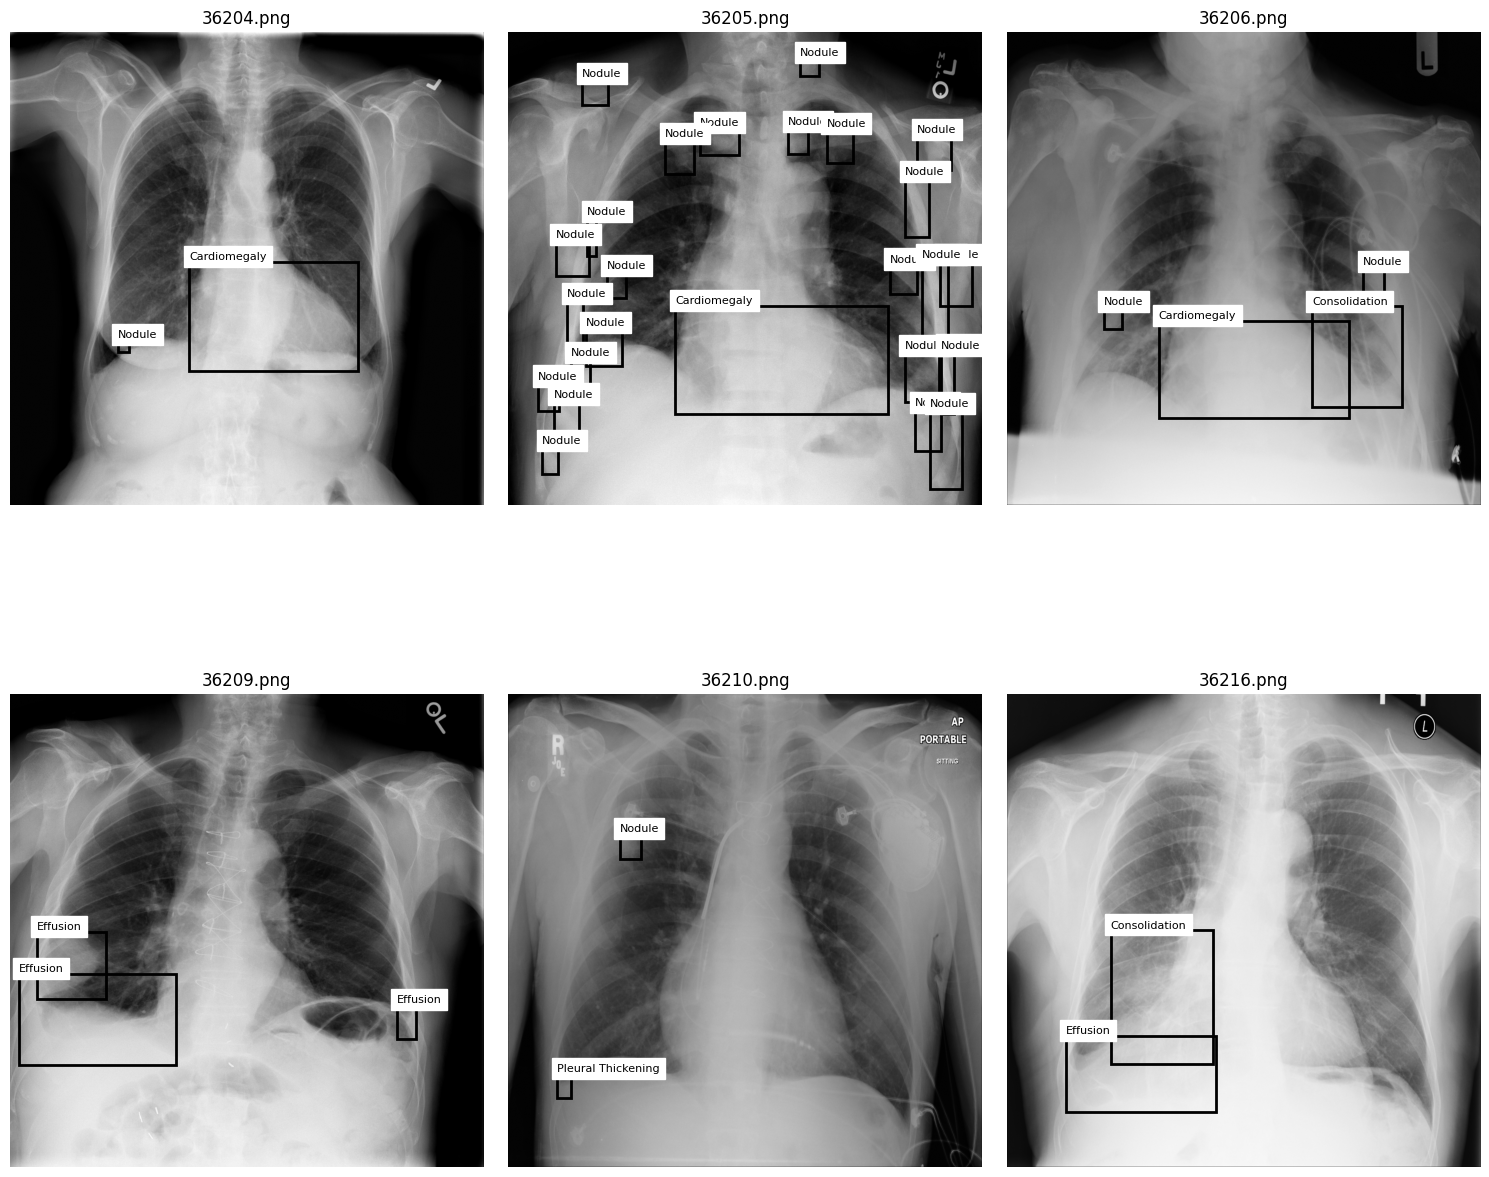

In [17]:
from matplotlib.patches import Rectangle

# Create class-to-color-independent labels
class_names = sorted(set(
    symbol
    for record in train_annotations + test_annotations
    for symbol in record.get("syms", [])
))

class_to_id = {
    class_name: idx
    for idx, class_name in enumerate(class_names)
}

# Select a few annotated images
sample_records = annotated_train[:6]

plt.figure(figsize=(15, 15))

for i, record in enumerate(sample_records):

    file_name = record["file_name"]

    # Find image
    image_path = None

    for root, dirs, files in os.walk(path):
        candidate = os.path.join(root, file_name)

        if os.path.exists(candidate):
            image_path = candidate
            break

    image = Image.open(image_path)

    ax = plt.subplot(2, 3, i + 1)

    ax.imshow(image, cmap="gray")

    for symbol, box in zip(record["syms"], record["boxes"]):

        x1, y1, x2, y2 = box

        width = x2 - x1
        height = y2 - y1

        rectangle = Rectangle(
            (x1, y1),
            width,
            height,
            fill=False,
            linewidth=2
        )

        ax.add_patch(rectangle)

        ax.text(
            x1,
            max(y1 - 5, 10),
            symbol,
            fontsize=8,
            backgroundcolor="white"
        )

    ax.set_title(file_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
def count_annotated(records):
    annotated = sum(
        len(record.get("boxes", [])) > 0
        for record in records
    )

    empty = len(records) - annotated

    return annotated, empty


train_annotated, train_empty = count_annotated(train_annotations)
test_annotated, test_empty = count_annotated(test_annotations)

print("TRAIN")
print("Annotated images:", train_annotated)
print("Empty images:", train_empty)

print("\nTEST")
print("Annotated images:", test_annotated)
print("Empty images:", test_empty)

TRAIN
Annotated images: 2478
Empty images: 547

TEST
Annotated images: 489
Empty images: 64


# encoding YOLO's classes

In [19]:
class_to_id = {
    name: idx
    for idx, name in enumerate(class_names)
}

print("Number of classes:", len(class_names))
print("\nClass mapping:")

for class_name, class_id in class_to_id.items():
    print(f"{class_id}: {class_name}")

Number of classes: 13

Class mapping:
0: Atelectasis
1: Calcification
2: Cardiomegaly
3: Consolidation
4: Diffuse Nodule
5: Effusion
6: Emphysema
7: Fibrosis
8: Fracture
9: Mass
10: Nodule
11: Pleural Thickening
12: Pneumothorax


# Create YOLO Folder Structure

In [20]:
YOLO_DIR = "/content/yolo_dataset"
folders = [
    f"{YOLO_DIR}/images/train",
    f"{YOLO_DIR}/images/val",
    f"{YOLO_DIR}/images/test",
    f"{YOLO_DIR}/labels/train",
    f"{YOLO_DIR}/labels/val",
    f"{YOLO_DIR}/labels/test"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("YOLO dataset folders created successfully.")

YOLO dataset folders created successfully.


# Train / Validation / test split

In [21]:
train_records, val_records = train_test_split(
    train_annotations,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Original train records:", len(train_annotations))
print("New train records:", len(train_records))
print("Validation records:", len(val_records))
print("Official test records:", len(test_annotations))

Original train records: 3025
New train records: 2420
Validation records: 605
Official test records: 553


# Find Image Path

In [22]:
image_paths = {}

for root, dirs, files in os.walk(path):
    for file in files:
        if file.lower().endswith(".png"):
            image_paths[file] = os.path.join(root, file)

print("Images indexed:", len(image_paths))

print("\nExample:")
for file_name, file_path in list(image_paths.items())[:5]:
    print(file_name, "->", file_path)

Images indexed: 3580

Example:
41463.png -> /kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/41463.png
59639.png -> /kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/59639.png
48828.png -> /kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/48828.png
45687.png -> /kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/45687.png
41141.png -> /kaggle/input/datasets/metformin/chexdet-image-and-annotations/test_data/test/41141.png


In [23]:
def convert_box_to_yolo(box, image_width, image_height):

    x1, y1, x2, y2 = box

    x_center = (x1 + x2) / 2
    y_center = (y1 + y2) / 2

    width = x2 - x1
    height = y2 - y1

    x_center /= image_width
    y_center /= image_height
    width /= image_width
    height /= image_height

    return x_center, y_center, width, height

# creating yolo's labels

In [24]:
def create_yolo_labels(records, label_dir):

    for record in records:

        file_name = record["file_name"]
        symbols = record.get("syms", [])
        boxes = record.get("boxes", [])

        label_file = os.path.join(
            label_dir,
            os.path.splitext(file_name)[0] + ".txt"
        )

        # Empty image
        if len(boxes) == 0:
            continue

        with Image.open(image_paths[file_name]) as img:
            image_width, image_height = img.size

        with open(label_file, "w") as f:

            for symbol, box in zip(symbols, boxes):

                class_id = class_to_id[symbol]

                x_center, y_center, width, height = \
                    convert_box_to_yolo(
                        box,
                        image_width,
                        image_height
                    )

                f.write(
                    f"{class_id} "
                    f"{x_center:.6f} "
                    f"{y_center:.6f} "
                    f"{width:.6f} "
                    f"{height:.6f}\n"
                )

In [25]:
create_yolo_labels(
    train_records,
    f"{YOLO_DIR}/labels/train"
)

create_yolo_labels(
    val_records,
    f"{YOLO_DIR}/labels/val"
)

create_yolo_labels(
    test_annotations,
    f"{YOLO_DIR}/labels/test"
)

print("YOLO labels created successfully.")

YOLO labels created successfully.


# copy images to YOLO

In [26]:
def copy_images(records, destination_dir):

    for record in records:

        file_name = record["file_name"]

        source = image_paths[file_name]

        destination = os.path.join(
            destination_dir,
            file_name
        )

        shutil.copy2(source, destination)


copy_images(
    train_records,
    f"{YOLO_DIR}/images/train"
)

copy_images(
    val_records,
    f"{YOLO_DIR}/images/val"
)

copy_images(
    test_annotations,
    f"{YOLO_DIR}/images/test"
)

print("Images copied successfully.")

Images copied successfully.


# counting images and labels

In [27]:
def count_files(folder, extension):

    return sum(
        1
        for file in os.listdir(folder)
        if file.lower().endswith(extension)
    )


for split in ["train", "val", "test"]:

    image_dir = f"{YOLO_DIR}/images/{split}"
    label_dir = f"{YOLO_DIR}/labels/{split}"

    image_count = count_files(image_dir, ".png")
    label_count = count_files(label_dir, ".txt")

    print(f"\n{split.upper()}")
    print("Images:", image_count)
    print("Labels:", label_count)


TRAIN
Images: 2420
Labels: 1985

VAL
Images: 605
Labels: 493

TEST
Images: 553
Labels: 489


# Verify image/label pairing

In [28]:
for split in ["train", "val", "test"]:
    image_dir = f"{YOLO_DIR}/images/{split}"
    label_dir = f"{YOLO_DIR}/labels/{split}"

    image_files = {
        os.path.splitext(f)[0]
        for f in os.listdir(image_dir)
        if f.endswith(".png")
    }

    label_files = {
        os.path.splitext(f)[0]
        for f in os.listdir(label_dir)
        if f.endswith(".txt")
    }

    print(f"\n{split.upper()}")
    print("Images:", len(image_files))
    print("Labels:", len(label_files))
    print("Images without labels:", len(image_files - label_files))
    print("Labels without images:", len(label_files - image_files))


TRAIN
Images: 2420
Labels: 1985
Images without labels: 435
Labels without images: 0

VAL
Images: 605
Labels: 493
Images without labels: 112
Labels without images: 0

TEST
Images: 553
Labels: 489
Images without labels: 64
Labels without images: 0


In [29]:
import os
import math
import shutil
from collections import Counter

# Count objects per class in the original training set
class_counts = Counter()

for record in train_records:
    for symbol in record.get("syms", []):
        class_counts[symbol] += 1

max_count = max(class_counts.values())

# Calculate a moderate repeat factor for each class
class_repeat = {}

for class_name, count in class_counts.items():
    repeat = math.ceil(math.sqrt(max_count / count))
    class_repeat[class_name] = min(repeat, 4)

print("Repeat factor per class:")
for class_name in class_names:
    print(f"{class_name}: {class_repeat[class_name]}")

# CHANGED: repeated copies are now photometric-augmented (brightness /
# contrast / mild noise) instead of exact pixel duplicates. Boxes are
# untouched on purpose -- these are photometric-only transforms, so the
# spatial layout (and therefore the YOLO box coordinates) does not change.
# This was the main fix for the oversized/imprecise boxes on rare classes
# (e.g. Emphysema): the model was previously seeing the exact same few
# images repeated verbatim and had nothing to generalize from.
def augment_image(img):
    img = img.convert("L")

    if random.random() < 0.7:
        factor = random.uniform(0.85, 1.15)
        img = ImageEnhance.Brightness(img).enhance(factor)

    if random.random() < 0.7:
        factor = random.uniform(0.85, 1.15)
        img = ImageEnhance.Contrast(img).enhance(factor)

    if random.random() < 0.3:
        arr = np.array(img).astype(np.float32)
        noise = np.random.normal(0, 5, arr.shape)
        arr = np.clip(arr + noise, 0, 255).astype(np.uint8)
        img = Image.fromarray(arr, mode="L")

    return img


# Rebuild training folders
train_image_dir = f"{YOLO_DIR}/images/train"
train_label_dir = f"{YOLO_DIR}/labels/train"

shutil.rmtree(train_image_dir, ignore_errors=True)
shutil.rmtree(train_label_dir, ignore_errors=True)

os.makedirs(train_image_dir, exist_ok=True)
os.makedirs(train_label_dir, exist_ok=True)

# Create oversampled training dataset
new_train_count = 0

for record in train_records:

    file_name = record["file_name"]
    symbols = record.get("syms", [])
    boxes = record.get("boxes", [])

    # Empty image -> keep it once
    if len(symbols) == 0:
        repeat_count = 1

    else:
        # Use the highest repeat factor among classes in this image
        repeat_count = max(
            class_repeat[symbol]
            for symbol in set(symbols)
        )

    source_image = image_paths[file_name]

    for i in range(repeat_count):

        base_name = os.path.splitext(file_name)[0]

        if i == 0:
            new_name = file_name
        else:
            new_name = f"{base_name}_dup{i}.png"

        destination_image = os.path.join(
            train_image_dir,
            new_name
        )

        if i == 0:
            # First copy: keep the original image untouched
            shutil.copy2(
                source_image,
                destination_image
            )
        else:
            # CHANGED: repeats get a fresh photometric augmentation each
            # time instead of an exact copy of the source pixels
            with Image.open(source_image) as src_img:
                augmented = augment_image(src_img)
                augmented.save(destination_image)

        # Create YOLO label
        if len(boxes) > 0:

            label_name = os.path.splitext(new_name)[0] + ".txt"
            label_path = os.path.join(
                train_label_dir,
                label_name
            )

            with open(label_path, "w") as f:

                for symbol, box in zip(symbols, boxes):

                    class_id = class_to_id[symbol]

                    x_center, y_center, width, height = convert_box_to_yolo(
                        box,
                        1024,
                        1024
                    )

                    f.write(
                        f"{class_id} "
                        f"{x_center:.6f} "
                        f"{y_center:.6f} "
                        f"{width:.6f} "
                        f"{height:.6f}\n"
                    )

        new_train_count += 1

print("\nOriginal training images:", len(train_records))
print("Balanced training images:", new_train_count)


Repeat factor per class:
Atelectasis: 3
Calcification: 3
Cardiomegaly: 4
Consolidation: 1
Diffuse Nodule: 4
Effusion: 2
Emphysema: 4
Fibrosis: 2
Fracture: 2
Mass: 4
Nodule: 2
Pleural Thickening: 2
Pneumothorax: 4

Original training images: 2420
Balanced training images: 5651


# creating yaml

In [30]:
data_yaml = f"""
path: {YOLO_DIR}

train: images/train
val: images/val
test: images/test

names:
  0: Atelectasis
  1: Calcification
  2: Cardiomegaly
  3: Consolidation
  4: Diffuse Nodule
  5: Effusion
  6: Emphysema
  7: Fibrosis
  8: Fracture
  9: Mass
  10: Nodule
  11: Pleural Thickening
  12: Pneumothorax
"""

with open(f"{YOLO_DIR}/data.yaml", "w") as f:
    f.write(data_yaml)

print(data_yaml)


path: /content/yolo_dataset

train: images/train
val: images/val
test: images/test

names:
  0: Atelectasis
  1: Calcification
  2: Cardiomegaly
  3: Consolidation
  4: Diffuse Nodule
  5: Effusion
  6: Emphysema
  7: Fibrosis
  8: Fracture
  9: Mass
  10: Nodule
  11: Pleural Thickening
  12: Pneumothorax



In [31]:
model = YOLO("yolo11s.pt")  # CHANGED: was yolo11n.pt

print("YOLO model loaded successfully.")

YOLO model loaded successfully.


# model trainig

In [32]:
model.train(
    data=f"{YOLO_DIR}/data.yaml",
    epochs=80,        # CHANGED: was 50
    imgsz=640,
    batch=8,
    patience=10,      # CHANGED: was 5 -- previous run may have stopped too early
    workers=2,
    seed=42,
    project="/content/yolo_runs",
    name="chexdet_yolo11s",   # CHANGED: was chexdet_yolo11n
    plots=True
)


Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=chexdet_yolo11s, nbs=64, nms=None, opset=None,

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 38/38 2.8it/s 13.5s.2s
                   all        605       1534       0.46      0.155     0.0995     0.0439

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/80      2.66G      1.895      2.768      1.793         27        640: 100% ━━━━━━━━━━━━ 707/707 8.2it/s 1:260.1sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 94% ━━━━━━━━━━━─ 36/38 6.6it/s 5.8s<0.3s

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 38/38 6.2it/s 6.1s0.2s
                   all        605       1534      0.354      0.166      0.126     0.0538

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/80      2.66G       1.86      2.623      1.765         17        640: 100% ━━━━━━━━━━━━ 707/707 8.2it/s 1:260.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 94% ━━━━━━━━━━━─ 36/38 6.8it/s 5.6s<0.3s

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


... (132 outputs left out)

                   all        605       1534      0.573      0.407      0.413      0.215
EarlyStopping: Training stopped early as no improvement observed in last 10 epochs. Best results observed at epoch 59, best model saved as best.pt.
To update EarlyStopping(patience=10) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

69 epochs completed in 1.781 hours.
Optimizer stripped from /content/yolo_runs/chexdet_yolo11s/weights/last.pt, 19.2MB
Optimizer stripped from /content/yolo_runs/chexdet_yolo11s/weights/best.pt, 19.2MB

Validating /content/yolo_runs/chexdet_yolo11s/weights/best.pt...
Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,417,831 parameters, 0 gradients, 21.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 97% ━━━━━━━━━━━╸ 37/38 6.3it/s 9.7s<0.2s

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 38/38 3.0it/s 12.8s
                   all        605       1534      0.541      0.432      0.424      0.218
           Atelectasis         46         57      0.387      0.333      0.303      0.123
         Calcification         30         53      0.467      0.396      0.311      0.116
          Cardiomegaly         41         41      0.773       0.61      0.696      0.489
         Consolidation        276        435      0.638      0.595      0.626      0.289
        Diffuse Nodule         28         42      0.651      0.381      0.418      0.251
              Effusion        233        340      0.555      0.609      0.591      0.243
             Emphysema         29         51      0.782      0.686      0.678       0.52
              Fibrosis         87        122      0.418      0.385      0.359      0.159
              Fracture         64        107      0.645      0.458     

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7959427dd610>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.04504

# loading the best checkpoint

In [33]:
BEST_MODEL_PATH = "/content/yolo_runs/chexdet_yolo11s/weights/best.pt"  # CHANGED: check the actual run folder name -- Ultralytics appends -2, -3... if you re-run training in the same session
best_model = YOLO(BEST_MODEL_PATH)

print("Best YOLO model loaded successfully.")

Best YOLO model loaded successfully.


# model evaluation

In [34]:
val_results = best_model.val(
    data=f"{YOLO_DIR}/data.yaml",
    split="val",
    imgsz=640,
    batch=8,
    plots=True
)

print("\nValidation Evaluation Completed.")

Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,417,831 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4036.5±1068.7 MB/s, size: 382.3 KB)
val: Scanning /content/yolo_dataset/labels/val.cache... 493 images, 112 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 605/605 211.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 96% ━━━━━━━━━━━╸ 73/76 9.3it/s 8.9s<0.3s

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 76/76 8.3it/s 9.2s0.1s
                   all        605       1534      0.547      0.432      0.425      0.219
           Atelectasis         46         57      0.403      0.333      0.303      0.126
         Calcification         30         53       0.48      0.396      0.313      0.116
          Cardiomegaly         41         41      0.775       0.61      0.697      0.491
         Consolidation        276        435      0.634      0.589      0.626      0.289
        Diffuse Nodule         28         42      0.673      0.392      0.422      0.254
              Effusion        233        340      0.556      0.607      0.591      0.244
             Emphysema         29         51      0.782      0.686      0.678      0.516
              Fibrosis         87        122      0.431      0.393      0.363      0.162
              Fracture         64        107      0.642      0.453  

In [35]:
print("Validation Metrics")
print("-" * 40)

print(f"Precision: {val_results.box.mp:.4f}")
print(f"Recall:    {val_results.box.mr:.4f}")
print(f"mAP50:     {val_results.box.map50:.4f}")
print(f"mAP50-95:  {val_results.box.map:.4f}")

Validation Metrics
----------------------------------------
Precision: 0.5467
Recall:    0.4322
mAP50:     0.4250
mAP50-95:  0.2188


Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,417,831 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3519.7±884.1 MB/s, size: 392.3 KB)
val: Scanning /content/yolo_dataset/labels/test... 489 images, 64 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 553/553 328.8it/s 1.7s0.1s
val: New cache created: /content/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 70/70 8.2it/s 8.5s0.1s
                   all        553       1734      0.565      0.398      0.403      0.215
           Atelectasis         48         51      0.328      0.275       0.24     0.0904
         Calcification         38         67        0.5      0.328      0.347      0.136
          Cardiomegaly         70         70       0.77      0.586      0.664      0.455
         Consolidation        293        453      0.616      

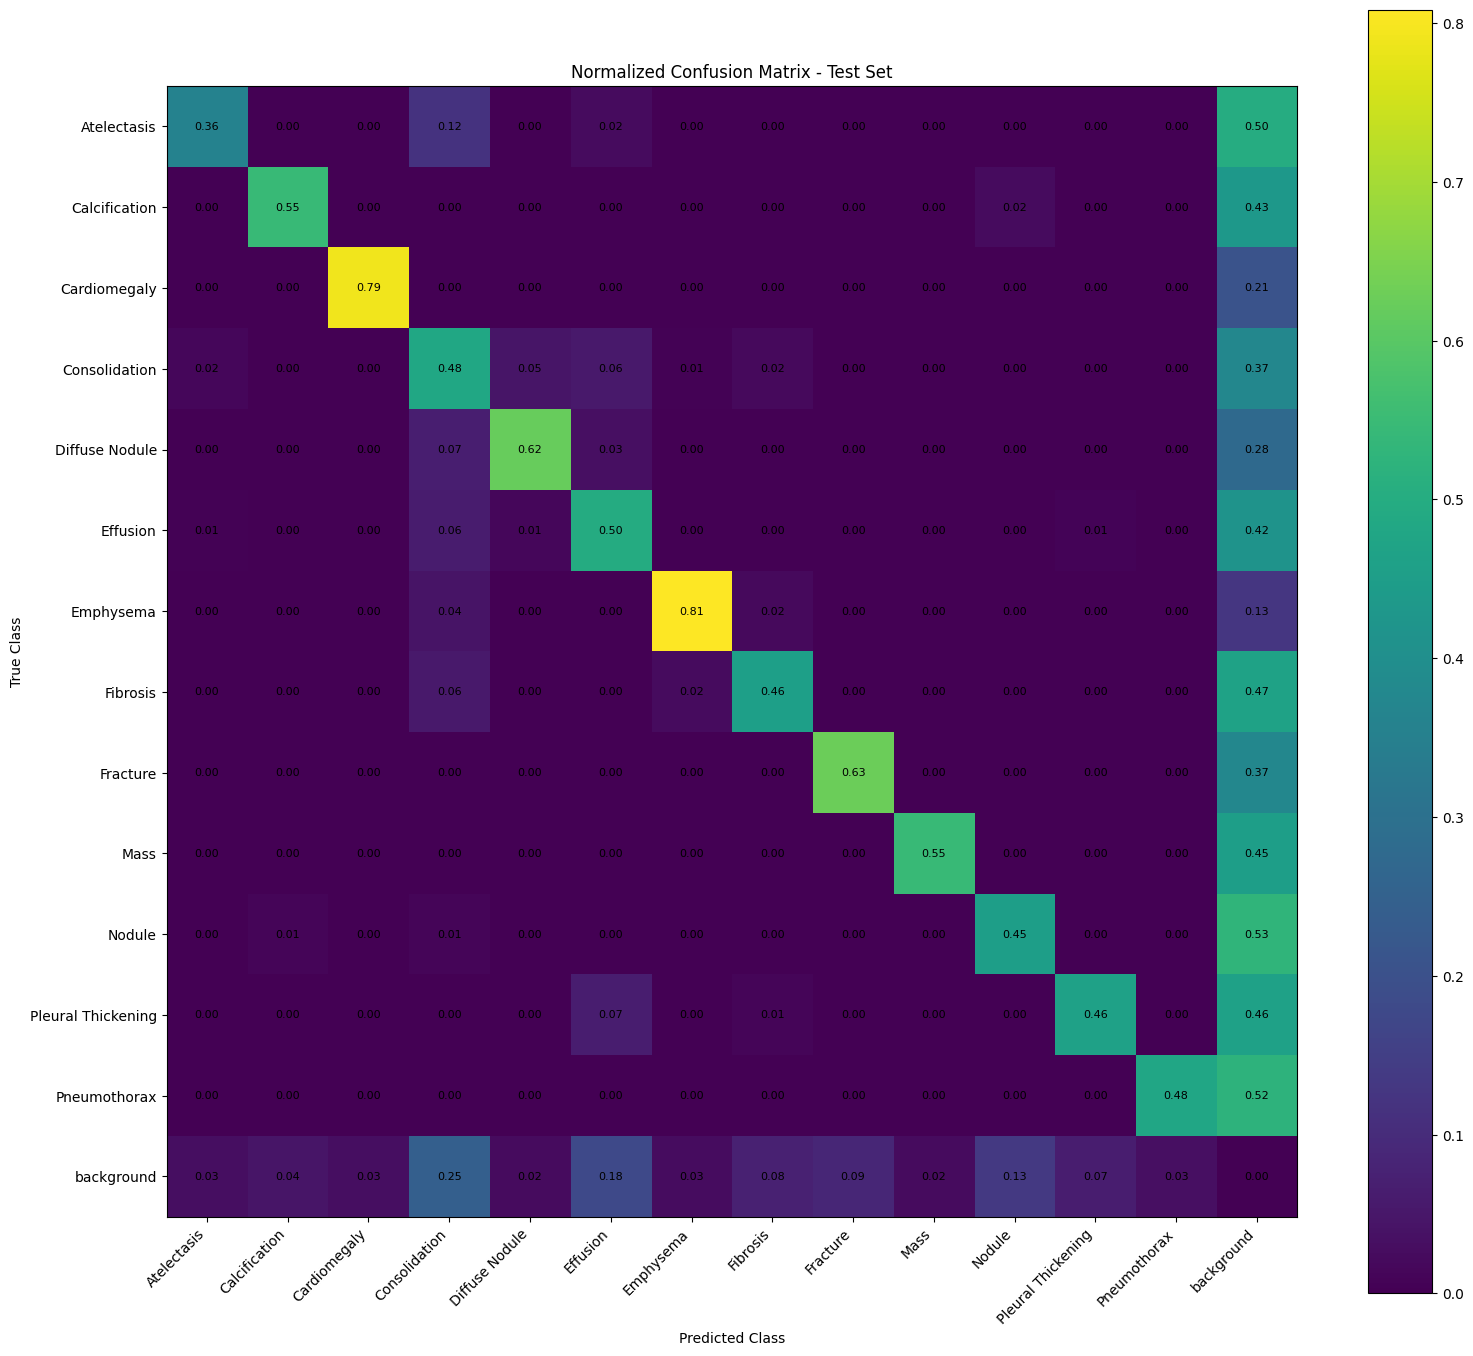

In [36]:
test_results = best_model.val(
    data=f"{YOLO_DIR}/data.yaml",
    split="test",
    imgsz=640,
    batch=8,
    plots=True
)
cm = test_results.confusion_matrix.matrix
class_names_with_bg = class_names + ["background"]

cm_normalized = cm / (cm.sum(axis=1, keepdims=True) + 1e-9)

fig, ax = plt.subplots(figsize=(16, 14))

im = ax.imshow(cm_normalized)

for i in range(cm_normalized.shape[0]):
    for j in range(cm_normalized.shape[1]):
        ax.text(
            j,
            i,
            f"{cm_normalized[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

ax.set_xticks(np.arange(len(class_names_with_bg)))
ax.set_yticks(np.arange(len(class_names_with_bg)))

ax.set_xticklabels(class_names_with_bg, rotation=45, ha="right")
ax.set_yticklabels(class_names_with_bg)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")
ax.set_title("Normalized Confusion Matrix - Test Set")

plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [37]:
print("FINAL TEST RESULTS")
print("=" * 40)

print(f"Precision: {test_results.box.mp:.4f}")
print(f"Recall:    {test_results.box.mr:.4f}")
print(f"mAP50:     {test_results.box.map50:.4f}")
print(f"mAP50-95:  {test_results.box.map:.4f}")

FINAL TEST RESULTS
Precision: 0.5654
Recall:    0.3984
mAP50:     0.4025
mAP50-95:  0.2149


In [38]:
prediction_files = glob.glob(
    "/content/yolo_predictions/test_predictions/*"
)

print("Number of saved predictions:", len(prediction_files))

sample_predictions = prediction_files[:6]

fig = plt.figure(figsize=(15, 10))

for i, file_path in enumerate(sample_predictions):

    image = Image.open(file_path)

    ax = fig.add_subplot(2, 3, i + 1)
    ax.imshow(image, cmap="gray")
    ax.axis("off")
    ax.set_title(os.path.basename(file_path))

plt.tight_layout()
plt.show()

Number of saved predictions: 0


<Figure size 1500x1000 with 0 Axes>

# saving model

In [39]:
BEST_MODEL_PATH = "/content/yolo_runs/chexdet_yolo11s/weights/best.pt"  # CHANGED: check the actual run folder name (Ultralytics may append -2, -3...)
SAVE_PATH = "/content/chexdet_yolo11s_best.pt"

shutil.copy2(BEST_MODEL_PATH, SAVE_PATH)

print("Model saved successfully.")
print("Path:", SAVE_PATH)
print("File exists:", os.path.exists(SAVE_PATH))

Model saved successfully.
Path: /content/chexdet_yolo11s_best.pt
File exists: True


In [45]:
model = YOLO('chexdet_yolo11s_best.pt')

print(f"Model task: {model.task}")
print(f"Number of classes: {len(model.names)}")
print(f"Class names: {model.names}")

Model task: detect
Number of classes: 13
Class names: {0: 'Atelectasis', 1: 'Calcification', 2: 'Cardiomegaly', 3: 'Consolidation', 4: 'Diffuse Nodule', 5: 'Effusion', 6: 'Emphysema', 7: 'Fibrosis', 8: 'Fracture', 9: 'Mass', 10: 'Nodule', 11: 'Pleural Thickening', 12: 'Pneumothorax'}


In [51]:
deployment_metadata = {
    'model_file': 'chexdet_yolo11s_best.pt',
    'class_names': model.names,
    'num_classes': len(model.names),
    'confidence_threshold': 0.25,
    'image_size': 640,
    'no_finding_message': 'No abnormal finding detected'
}

with open('chexdet_deployment_metadata.json', 'w') as f:
    json.dump(deployment_metadata, f, indent=2)

print("Metadata saved: chexdet_deployment_metadata.json")

Metadata saved: chexdet_deployment_metadata.json


In [50]:
import shutil
import os

OUTPUT_DIR = "/kaggle/working"

# انسخ الموديل بس
shutil.copy2(BEST_MODEL_PATH, os.path.join(OUTPUT_DIR, "chexdet_yolo11s_best.pt"))

# الـ metadata أصلًا موجود في /kaggle/working، مفيش داعي ننسخه
print("Files in /kaggle/working:")
print(os.listdir(OUTPUT_DIR))

Files in /kaggle/working:
['chexdet_deployment_metadata.json', 'runs', '.virtual_documents', 'chexdet_yolo11s_best.pt', 'yolo11s.pt', 'weights']


## 📌 Project Summary

The project applies **YOLO11** to perform object detection on the ChestX-Det dataset. The workflow included loading and analyzing the annotations, validating bounding boxes, examining class distribution, converting the annotations into YOLO format, preparing the dataset, and training the detection model.

To address the class imbalance in the training data, moderate oversampling was applied to the training set only, while the validation and test sets were kept unchanged.

**Update:** the oversampling step was revised to apply photometric augmentation (brightness/contrast jitter, mild noise) to each repeated copy instead of duplicating the raw pixels. The earlier duplication-based approach caused the model to memorize a handful of large ground-truth boxes for rare, diffuse classes (e.g. Emphysema) rather than generalizing, which showed up as oversized/imprecise boxes at inference. The base model was also upgraded from `yolo11n` to `yolo11s` for extra capacity, and training was extended (epochs 50 -> 80, patience 5 -> 10) since the previous run may have stopped early.

### Test Performance

*Re-run this notebook end-to-end to populate this section with the new model's metrics (Precision, Recall, mAP@50, mAP@50-95) -- the previous numbers (Precision 0.381, Recall 0.344, mAP@50 0.329, mAP@50-95 0.180) belonged to the earlier `yolo11n` + duplication-based run and are no longer representative.*

The final model was evaluated using detection metrics, confusion matrices, precision/recall curves, and prediction visualizations. The best-performing checkpoint (`best.pt`) was selected as the final trained model.
